<a href="https://colab.research.google.com/github/diseasemodeling/MIE_525_625/blob/main/Lectures/6b_PINN_InverseProblem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PROBLEM SETTING (EPIDEMIC EXAMPLE -S,I,R model)
$$[y_1, y_2, y_3]=[S,I,R]$$
  $$\frac{dS}{dt} = (-\beta  S  I)$$
  $$ \frac{dI}{dt} = (\beta  S  I - \gamma  I)$$
  $$ \frac{dR}{dt} = (\gamma  I)$$

  We assume **we do not know**
  - $\beta$
  - functional form of $\frac{dR}{dt}$

### OBJECTIVE: INVERSE PROBLEM
- Use PINN to learn blackbox function of $dy_3/dt$ and value of $\beta$, and


In [ ]:
!pip install torchdiffeq

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchdiffeq import odeint # Used only to generate true comparison data
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

## PINN
### NEURAL NETWORK ARCHITECTURE :
- x-net is a newtork to represent $x=f(t)$;
- f_net is a network to represent $f_s=f(t,x)$

Setup Y-Net training. Input layer is 't' output layer are the states 'y'. NUmber in outlayer should match with number of state variables

In [ ]:
# ── Y-Net: maps t → [y1, y2, y3] ────────────────────────────────────────
class YNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 50), nn.Tanh(),
            nn.Linear(50, 50), nn.Tanh(),
            nn.Linear(50, 3),
        )

    def forward(self, t):
        return self.net(t)

f_net takes 'y'(states) and 't' (time) in input layer and outputs $\dot{y}$ of the unknown function  ($\dot{x_3}$ in our case).

In [ ]:
# ── F-Net: maps [t, y1, y2. y3] → scalar f  (behavioral response) ───────
class FNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 50), nn.Tanh(),
            nn.Linear(50, 50), nn.Tanh(),
            nn.Linear(50, 1),
        )

    def forward(self, t, y):
        inp = torch.cat([t, y], dim=1)
        return self.net(inp)

Put it together in PINN. Add the uknown coefficients to the output using the parameter layer, so it can part of the parameters to train.

In [ ]:
# ── Full PINN ─────────────────────────────────────────────────────────────────
class EpiNet(nn.Module):
    def __init__(self, beta0_init: float = 0.1):
        super().__init__()
        self.y_net = YNet()
        self.f_net = FNet()
        # Learnable scalar β₀
        self.beta0 = nn.Parameter(torch.tensor([beta0_init], dtype=torch.float32))

    def forward(self, t):
        y = self.y_net(t)
        f = self.f_net(t, y)
        return y, f

###Generate synthetic data for model training (or upload true data)

In [ ]:
# Setup known epidemic constants and true data for comparison
gamma =  0.1 # In this example, we assume we know these parameters- which are the coefficients in the ODEs.
initial_state = torch.tensor([0.99, 0.01, 0.00])

# Actual data available for training: suppose we only have data for these timesteps
t_data = torch.tensor([15., 16., 18., 20.]).unsqueeze(dim=1)

#------------------
# Generate a dense set of physics collocation points, ensuring t_data points are included
t_physics_base = torch.linspace(0., 30., 200).view(-1)
t_physics_combined = torch.unique(torch.cat((t_physics_base, t_data.view(-1)))).sort().values# Combine with t_data points to ensure exact matches are present#
t_physics = t_physics_combined.view(-1, 1).requires_grad_(True)# Convert to a column vector and enable gradient tracking for physics loss

#------------------
# Compute true_y for validation: True y is not typically available - creating here for demonstration.
def true_sir_dynamics(t, y):
    beta =0.3
    S, I, R = y[0], y[1], y[2]
    return torch.stack([-beta*S*I, beta*S*I - gamma*I, gamma*I])
true_y = odeint(true_sir_dynamics, initial_state, t_physics.detach().view(-1))

#------------------
# Extract train_y by finding the exact indices of t_data within t_physics
time_mask = torch.isin(t_physics.detach().view(-1), t_data.view(-1))
matching_indices = torch.nonzero(time_mask).squeeze()
train_y = true_y[matching_indices, :]

In [ ]:
# Collocation points for ODE loss
# Set up simulation
t_span = [0, 30]
obs_num = 1000

N_collocation = 10000
ODE_batch_size = 1000
X_train_ODE = torch.linspace(t_span[0], t_span[1], N_collocation).unsqueeze(1)
ode_dataset = TensorDataset(X_train_ODE)
ode_loader = DataLoader(ode_dataset, batch_size=ODE_batch_size, shuffle=True)

# Observed data for data loss
data_batch_size = 10
X_train_data = torch.tensor(t_data, dtype=torch.float32)
y_train_data = torch.tensor(train_y, dtype=torch.float32)
data_dataset = TensorDataset(X_train_data, y_train_data)
data_loader = DataLoader(data_dataset, batch_size=data_batch_size, shuffle=True)

/tmp/ipykernel_812/367398490.py:14: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_train_data = torch.tensor(t_data, dtype=torch.float32)
/tmp/ipykernel_812/367398490.py:15: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_train_data = torch.tensor(train_y, dtype=torch.float32)


### PINN TRAIN

In [ ]:
epi_pinn = EpiNet()
optimizer = optim.Adam(epi_pinn.parameters(), lr=0.001)

In [ ]:
epochs = 1500
for epoch in range(epochs):
    optimizer.zero_grad()

    # -------------------------------------------------------------------------
    # 1. DATA LOSS (Comparing sparse model predictions against actual measurements)
    # -------------------------------------------------------------------------
    pred_y,_  = epi_pinn(t_data)
    loss_data = torch.mean((pred_y - train_y) ** 2)

    # -------------------------------------------------------------------------
    # 2. PHYSICS LOSS (Using a denser grid of collocation points to enforce laws)
    # -------------------------------------------------------------------------
    pred_phys, pred_unknown_f= epi_pinn(t_physics)
    S_p, I_p, R_p = pred_phys[:, 0:1], pred_phys[:, 1:2], pred_phys[:, 2:3]

    # Compute derivatives from predicted values via autograd
    dS_dt = torch.autograd.grad(S_p, t_physics, torch.ones_like(S_p), create_graph=True)[0]
    dI_dt = torch.autograd.grad(I_p, t_physics, torch.ones_like(I_p), create_graph=True)[0]
    dR_dt = torch.autograd.grad(R_p, t_physics, torch.ones_like(R_p), create_graph=True)[0]


    # Physics residuals (
    beta = epi_pinn.beta0 #get from learned NN
    f = pred_unknown_f #get from learned NN
    f_S = dS_dt - (-beta * S_p * I_p)
    f_I = dI_dt - (beta * S_p * I_p - gamma * I_p)
    f_R = dR_dt - f
    loss_physics = torch.mean(f_S**2) + torch.mean(f_I**2) + torch.mean(f_R**2)

    # -------------------------------------------------------------------------
    # 3. INITIAL CONDITION LOSS
    # -------------------------------------------------------------------------
    t_zero = torch.tensor([[0.0]])
    pred_zero, _ = epi_pinn(t_zero)
    loss_initial = torch.mean((pred_zero - initial_state)**2)

    # -------------------------------------------------------------------------
    # TOTAL LOSS: Balances observations + structural physics constraints
    # -------------------------------------------------------------------------
    total_loss = 1 * loss_data + 2.0 * loss_physics + 1 * loss_initial

    total_loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch} | Data Loss: {loss_data.item():.6f} | Physics Loss: {loss_physics.item():.6f}")

epi_pinn.eval()
with torch.no_grad():
    pred_y_PINN,_  = epi_pinn(t_physics) #predict for full time range

Epoch 0 | Data Loss: 0.160730 | Physics Loss: 0.006412
Epoch 500 | Data Loss: 0.000129 | Physics Loss: 0.000039
Epoch 1000 | Data Loss: 0.000031 | Physics Loss: 0.000030


## Regular NN train- only use data loss

In [ ]:
epi_nn = EpiNet()
optimizer = optim.Adam(epi_nn.parameters(), lr=0.001)
epochs = 1500
for epoch in range(epochs):
    optimizer.zero_grad()

    # -------------------------------------------------------------------------
    # 1. DATA LOSS (Comparing sparse model predictions against actual measurements)
    # -------------------------------------------------------------------------
    pred_data, _ = epi_nn(t_data)
    loss_data = torch.mean((pred_data - train_y) ** 2)

    total_loss = 1 * loss_data
    total_loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch} | Data Loss: {loss_data.item():.6f}")
epi_nn.eval()
with torch.no_grad():
    pred_y_NN, _ = epi_nn(t_physics) #predict for full time range

Epoch 0 | Data Loss: 0.520000
Epoch 500 | Data Loss: 0.000103
Epoch 1000 | Data Loss: 0.000008


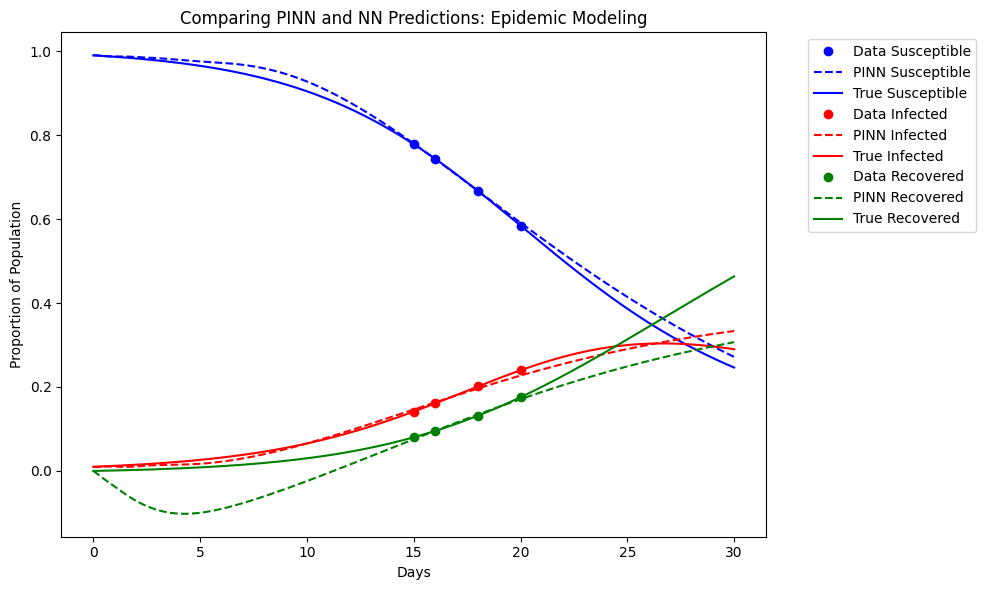

In [ ]:
# Plot  Predictions vs Ground Truth
plt.figure(figsize=(10, 6))
labels = ['Susceptible', 'Infected', 'Recovered']
colors = ['blue', 'red', 'green']

for i in range(3):
    plt.plot(t_data.numpy(), train_y[:, i].numpy(), label=f'Data {labels[i]}', color=colors[i], marker='o', linestyle='None' )
    plt.plot(t_physics.detach().numpy(), pred_y_PINN[:, i].numpy(), label=f'PINN {labels[i]}', color=colors[i], linestyle='--')
    #plt.plot(t_physics.detach().numpy(), pred_y_NN[:, i].numpy(), label=f'NN {labels[i]}', color=colors[i], linestyle='-.', marker='x')
    plt.plot(t_physics.detach().numpy(), true_y[:, i].numpy(), label=f'True {labels[i]}', color=colors[i])
plt.title('Comparing PINN and NN Predictions: Epidemic Modeling')
plt.xlabel('Days')
plt.ylabel('Proportion of Population')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()